# 行为阿尔法前沿（BAF）研究教程

本教程用**虚构**的每日持仓，演示参考公开 EBAB/EBAF 论文独立重建的 BAF。七类决策的公式均在[方法说明](../../docs/source/behavioral-alpha-frontier.md)中列出。论文没有公开全部商业算法和综合评分映射，因此本项目不声称复现官方分数或同业排名。

## 1. 读取本地数据

每行对应一个账户、证券和交易日，清仓后仍有零持仓价格行。价格与股数须采用一致的复权口径。字段名可直接传给 `prepare_baf`，无需重命名输入列。

In [1]:
from pathlib import Path
import sys
import polars as pl
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/baf/synthetic_daily_positions.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run scripts/generate_baf_data.py first')
sys.path.insert(0, str(ROOT / 'src'))

# Jupyter may retain an older brinsons import after the project is edited.
import importlib
import brinsons
import brinsons.baf
importlib.reload(brinsons.baf)
importlib.reload(brinsons)

from brinsons import (
    prepare_baf, calculate_baf, stock_picking_decisions, sizing_decisions,
    entry_timing_decisions, scaling_in_decisions, size_adjusting_decisions,
    scaling_out_decisions, exit_timing_decisions, decision_metrics, plot_baf,
    payoff_scale, inverse_payoff_scale, normalized_edge,
    baf_change_table, chart_baf_change_table,
)
grid = pl.read_csv(ROOT / 'data/baf/synthetic_daily_positions.csv', try_parse_dates=True)
print('Daily rows:', grid.height, '| portfolios:', grid['portfolio'].n_unique())
display(grid.head(5))

Daily rows: 4320 | portfolios: 3


portfolio,date,security,shares,price,benchmark_level
str,date,str,f64,f64,f64
"""Manager 1""",2025-01-02,"""FICTIONAL_1""",0.0,74.91,100.04
"""Manager 1""",2025-01-02,"""FICTIONAL_2""",0.0,82.32214,100.04
"""Manager 1""",2025-01-02,"""FICTIONAL_3""",0.0,89.48952,100.04
"""Manager 1""",2025-01-02,"""FICTIONAL_4""",0.0,96.254399,100.04
"""Manager 1""",2025-01-02,"""FICTIONAL_5""",0.0,102.779494,100.04


## 2. 构造完整持仓段

清仓至零结束一个 episode；同一证券再次买入会开启新 episode。模拟数据中每个账户、证券组合都有两段完整持仓。

In [2]:
prepared = prepare_baf(
    grid,
    column_portfolio='portfolio', column_date='date', column_security='security',
    column_shares='shares', column_price='price',
    column_benchmark_level='benchmark_level',
    open_episode_policy='error',
)
print('Closed episodes:', prepared.episodes.height)
display(prepared.episodes.head(10))

Closed episodes: 48


portfolio,security,episode,entry_date,last_active_date,peak_shares,active_observations,exit_date
str,str,u32,date,date,f64,u32,date
"""Manager 1""","""FICTIONAL_1""",1,2025-01-08,2025-03-11,100.0,45,2025-03-12
"""Manager 1""","""FICTIONAL_1""",2,2025-04-24,2025-06-25,90.0,45,2025-06-26
"""Manager 1""","""FICTIONAL_2""",1,2025-01-09,2025-03-12,105.0,45,2025-03-13
"""Manager 1""","""FICTIONAL_2""",2,2025-04-25,2025-06-26,90.0,45,2025-06-27
"""Manager 1""","""FICTIONAL_3""",1,2025-01-10,2025-03-13,110.0,45,2025-03-14
"""Manager 1""","""FICTIONAL_3""",2,2025-04-28,2025-06-27,90.0,45,2025-06-30
"""Manager 1""","""FICTIONAL_4""",1,2025-01-13,2025-03-14,115.0,45,2025-03-17
"""Manager 1""","""FICTIONAL_4""",2,2025-04-29,2025-06-30,90.0,45,2025-07-01
"""Manager 1""","""FICTIONAL_5""",1,2025-01-08,2025-03-11,120.0,45,2025-03-12


## 3. 分别调用七类决策函数

每类方法都有独立的计算入口。`forward_days=21` 表示 21 个有数据的交易日；三个 phase fraction 控制建仓、调整与退出阶段划分。各反事实定义见[方法说明](../../docs/source/behavioral-alpha-frontier.md)。

In [3]:
separate = {
    'stock_picking': stock_picking_decisions(prepared),
    'sizing': sizing_decisions(prepared),
    'entry_timing': entry_timing_decisions(prepared, forward_days=21),
    'scaling_in': scaling_in_decisions(prepared, phase_fraction=0.9),
    'size_adjusting': size_adjusting_decisions(prepared, phase_fraction=0.9),
    'scaling_out': scaling_out_decisions(prepared, phase_fraction=0.9),
    'exit_timing': exit_timing_decisions(prepared, forward_days=21),
}
display(pl.DataFrame({'decision_type': list(separate),
                      'n_decisions': [frame.height for frame in separate.values()]}))
display(separate['stock_picking'].head(5))

decision_type,n_decisions
str,i64
"""stock_picking""",48
"""sizing""",48
"""entry_timing""",48
"""scaling_in""",48
"""size_adjusting""",48
"""scaling_out""",48
"""exit_timing""",48


portfolio,security,episode,decision_type,value_added
str,str,u32,str,f64
"""Manager 1""","""FICTIONAL_1""",1,"""stock_picking""",-0.028367
"""Manager 1""","""FICTIONAL_1""",2,"""stock_picking""",-0.028638
"""Manager 1""","""FICTIONAL_2""",1,"""stock_picking""",-0.027325
"""Manager 1""","""FICTIONAL_2""",2,"""stock_picking""",-0.04065
"""Manager 1""","""FICTIONAL_3""",1,"""stock_picking""",-0.052832


## 4. 计算命中率与盈亏比

对决策值 $y_i$，命中率为 $\#\{y_i\ge0\}/n$，盈亏比为 $\operatorname{mean}(y_i\mid y_i\ge0)/|\operatorname{mean}(y_i\mid y_i<0)|$。本项目采用缩放函数 $S_k(P)=P^k/(1+P^k)$，默认 $k=1.5$；论文未公开精确变换。无法定义盈亏比时返回空值。`all_decisions` 是描述性合并点。

In [4]:
result = calculate_baf(
    prepared,
    entry_forward_days=21, exit_forward_days=21,
    scaling_in_fraction=0.9, size_adjusting_fraction=0.9,
    scaling_out_fraction=0.9, minimum_decisions=5,
    payoff_scale_exponent=1.5,
)
assert result.decisions.height == sum(frame.height for frame in separate.values())
display(result.decisions.head(12))
display(result.metrics.select('portfolio', 'decision_type', 'n_decisions',
                              'hit_rate', 'payoff', 'scaled_payoff',
                              'mean_value_added'))

portfolio,security,episode,decision_type,value_added
str,str,u32,str,f64
"""Manager 1""","""FICTIONAL_1""",1,"""stock_picking""",-0.028367
"""Manager 1""","""FICTIONAL_1""",2,"""stock_picking""",-0.028638
"""Manager 1""","""FICTIONAL_2""",1,"""stock_picking""",-0.027325
"""Manager 1""","""FICTIONAL_2""",2,"""stock_picking""",-0.04065
"""Manager 1""","""FICTIONAL_3""",1,"""stock_picking""",-0.052832
…,…,…,…,…
"""Manager 1""","""FICTIONAL_4""",2,"""stock_picking""",-0.056242
"""Manager 1""","""FICTIONAL_5""",1,"""stock_picking""",-0.037505
"""Manager 1""","""FICTIONAL_5""",2,"""stock_picking""",-0.003847


portfolio,decision_type,n_decisions,hit_rate,payoff,scaled_payoff,mean_value_added
str,str,u32,f64,f64,f64,f64
"""Manager 1""","""all_decisions""",112,0.526786,1.117775,0.541656,0.002556
"""Manager 2""","""all_decisions""",112,0.491071,1.22076,0.574249,0.001963
"""Manager 3""","""all_decisions""",112,0.517857,0.977598,0.491504,0.000592
"""Manager 1""","""entry_timing""",16,0.4375,0.892666,0.457524,-0.00616
"""Manager 2""","""entry_timing""",16,0.375,0.677212,0.357862,-0.013422
…,…,…,…,…,…,…
"""Manager 2""","""sizing""",16,0.5,1.104043,0.537049,0.000155
"""Manager 3""","""sizing""",16,0.5625,1.372404,0.61653,0.001056
"""Manager 1""","""stock_picking""",16,0.375,1.806019,0.708206,0.002083


## 5. 绘制与数据点无关的无差异色带

背景色带是固定 $(h,S_k(P))$ 网格上的**归一化增值** $E(h,P)=hP-(1-h)$ 等值线，与经理散点数据无关。粗虚线 $E=0$ 经过 $(0.5,0.5)$；当 $k=1.5$ 时呈弯曲状，在 $h=0.25$ 处高度约 $0.839$。色带层级和缩放参数都只是示意假设，并非 Essentia 官方曲线。正增值区域在虚线右上方；不同经理的归一化增值相同不代表原始收益相同。

Chance curve at hit rate 0.25: 0.839


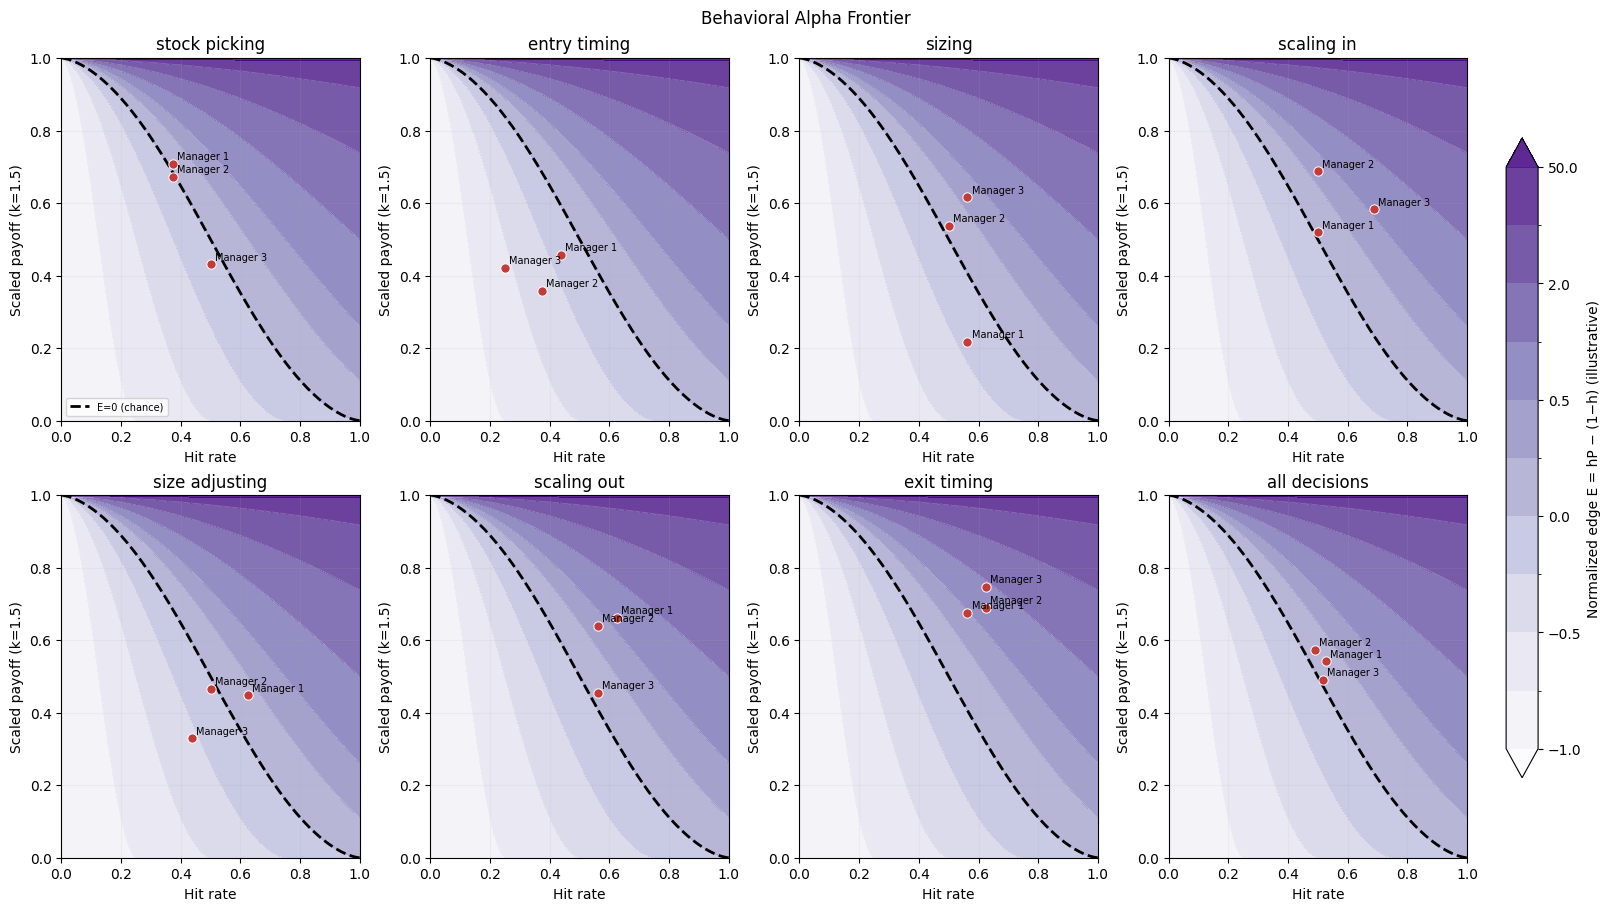

In [5]:
# The background is E(h,P)=h*P-(1-h), computed without manager data.
exponent = result.payoff_scale_exponent
chance_payoff = (1 - 0.25) / 0.25
chance_scaled = payoff_scale(chance_payoff, exponent=exponent)
print('Chance curve at hit rate 0.25:', round(chance_scaled, 3))
assert abs(normalized_edge(0.25, inverse_payoff_scale(chance_scaled, exponent=exponent))) < 1e-12

fig, axes = plot_baf(
    result,
    contour_levels=(-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 1, 2, 5, 50),
    grid_size=161,
    cmap='Purples',
)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 6. 可选的完整 episode 时间窗口

先从完整历史构造 episode，再按窗口筛选。论文采用每季度滚动 36 个月及额外数据覆盖条件；此处仅展示较简单的完整持仓段筛选。

In [6]:
# A completed-episode window; the full grid remains available for post-exit prices.
from datetime import date
windowed = calculate_baf(prepared, window_start=date(2025, 4, 1),
                         entry_forward_days=21, exit_forward_days=21,
                         minimum_decisions=1)
print('Episodes fully inside the window:', windowed.prepared.episodes.height)
display(windowed.metrics.select('portfolio', 'decision_type', 'n_decisions',
                                'hit_rate', 'scaled_payoff'))

Episodes fully inside the window: 24


portfolio,decision_type,n_decisions,hit_rate,scaled_payoff
str,str,u32,f64,f64
"""Manager 1""","""all_decisions""",56,0.535714,0.532856
"""Manager 2""","""all_decisions""",56,0.535714,0.519562
"""Manager 3""","""all_decisions""",56,0.535714,0.473247
"""Manager 1""","""entry_timing""",8,0.625,0.50427
"""Manager 2""","""entry_timing""",8,0.375,0.526883
…,…,…,…,…
"""Manager 2""","""sizing""",8,0.5,0.553073
"""Manager 3""","""sizing""",8,0.625,0.743715
"""Manager 1""","""stock_picking""",8,0.375,0.724192


## 7. 可视化同业变化表

参考论文 Exhibit 8 的**排版结构**，对同一批具备有效指标的经理比较两个窗口。三列分别是：实现正平均决策增值的账户占比、命中率超过 50% 的账户占比、Payoff 大于 1 的账户占比。数值为**本期百分比减去上期百分比**，显示为 `%`，不是相对增长率。绿色代表上升，粉色代表下降。这里是虚构代理结果，不是论文公布的百分比或商业 Decision Alpha。

decision_type,n_common_portfolios,adding_value_change_percent,hit_rate_positive_change_percent,payoff_positive_change_percent
str,u32,f64,f64,f64
"""all_decisions""",3,0.0,66.666667,-33.333333
"""entry_timing""",3,33.333333,33.333333,66.666667
"""exit_timing""",3,-33.333333,-33.333333,-33.333333
"""scaling_in""",3,-66.666667,-33.333333,-66.666667
"""scaling_out""",3,66.666667,100.0,66.666667
"""size_adjusting""",3,100.0,66.666667,100.0
"""sizing""",3,0.0,0.0,33.333333
"""stock_picking""",3,0.0,0.0,0.0


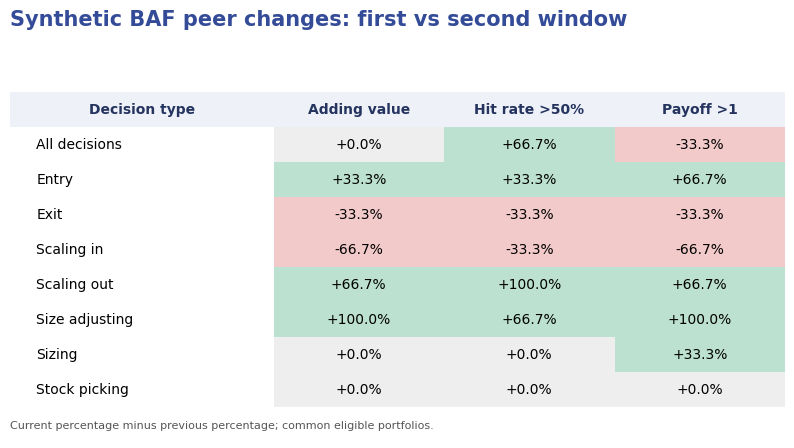

In [7]:
# Exhibit-8-style changes across common managers in two completed-episode windows.
from datetime import date
early = calculate_baf(prepared, window_end=date(2025, 4, 1))
late = calculate_baf(prepared, window_start=date(2025, 4, 1))
changes = baf_change_table(early, late)
display(changes)
fig, ax = chart_baf_change_table(
    changes, title='Synthetic BAF peer changes: first vs second window'
)
display(fig)
plt.close(fig)

## 解释边界

决策值**不是可加总的 Brinson 效应**，也不与组合超额收益勾稽。虚构结果不可与论文实证百分比或 Essentia 行为阿尔法分数比较。用于其他数据前请阅读[公式说明](../../docs/source/behavioral-alpha-frontier.md)。